# Exercise 1b — Denoising Autoencoder

**Goal:** justify an architecture and evaluate its ability to remove different levels of noise from the 32 font characters.

Noisy image → encoder → latent code → decoder → clean target.

The notebook moves from an initial model to a clean-trained reference, architecture comparisons, training-noise selection and final evaluation. The 2D latent-space restriction belongs to 1a; here we also investigate larger latent spaces.

## 0. Setup
Use the project environment. Restart the kernel after changing `src/tp5/autoencoder.py`.

In [2]:
from pathlib import Path
import inspect
import numpy as np
import matplotlib.pyplot as plt

from tp5.autoencoder import Autoencoder, Adam
from tp5.data import load_font, add_noise, pixel_errors, show_letters

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
FONT_PATH = ROOT / "data" / "font.h"
plt.rcParams["figure.dpi"] = 110

## 1. Clean data
The dataset contains 32 binary characters, each represented by 35 pixels (7 × 5). These clean images remain the reconstruction targets.

Shape: (32, 35)
Pixel values: [0. 1.]


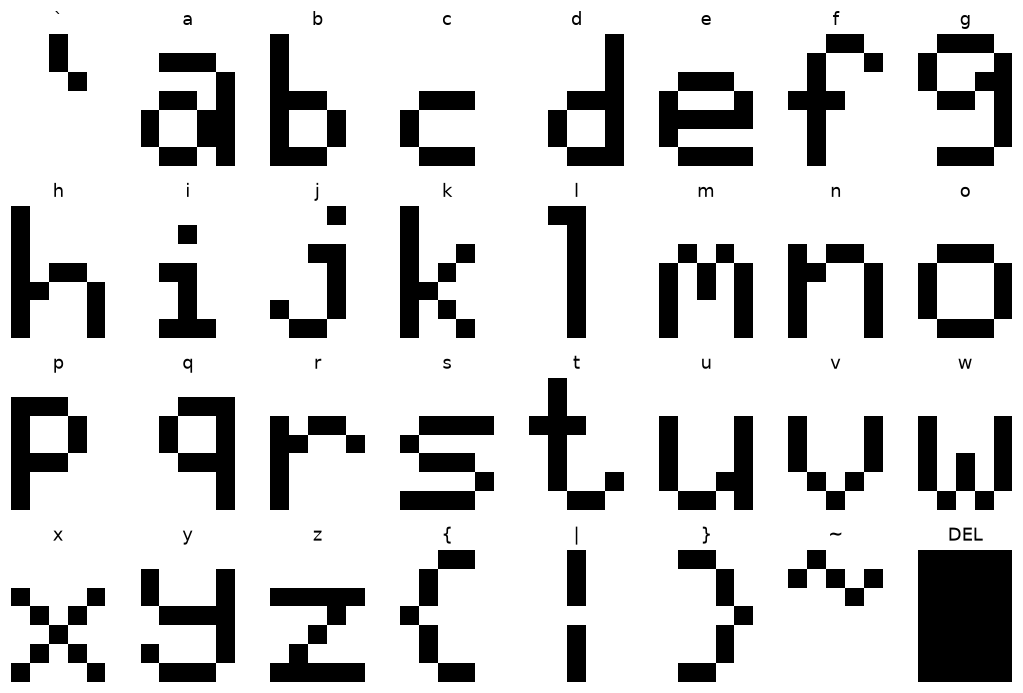

In [3]:
X_clean, chars = load_font(FONT_PATH)
X_clean = X_clean.astype(float)
print("Shape:", X_clean.shape)
print("Pixel values:", np.unique(X_clean))
show_letters(X_clean, titles=chars);

## 2. Noise process
Each pixel is independently flipped with probability `p`. At 10% noise, a character has 3.5 flipped pixels on average. The following preview uses a fixed seed for reproducibility.

Input errors per character: mean=2.94, max=5


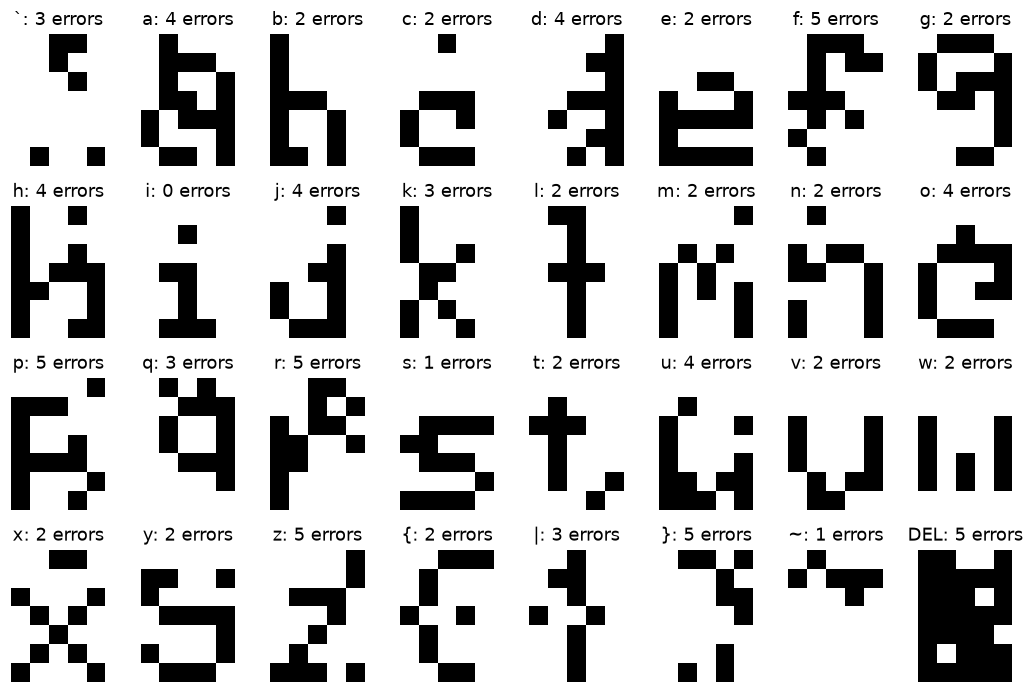

In [4]:
PREVIEW_NOISE = 0.10
preview_rng = np.random.default_rng(100)
X_preview = add_noise(X_clean, PREVIEW_NOISE, rng=preview_rng)
preview_errors = pixel_errors(X_clean, X_preview)
print(f"Input errors per character: mean={preview_errors.mean():.2f}, max={preview_errors.max()}")
show_letters(X_preview, titles=[f"{c}: {e} errors" for c, e in zip(chars, preview_errors)]);

## 3. Denoising implementation
`Autoencoder.fit()` generates fresh noisy inputs for each batch and calls `gradients(noisy_batch, clean_batch)`. The targets remain clean; `noise_level=0.0` supports ordinary autoencoder training.

The recorded training loss uses **clean inputs**. Noise-removal performance is evaluated separately below.

In [5]:
denoising_ready = "noise_level" in inspect.signature(Autoencoder.fit).parameters
print("fit() supports noise_level:", denoising_ready)


fit() supports noise_level: True


## 4. Initial model
Start from the 1a architecture: **35–20–10–2–10–20–35**.

| Setting | Value |
|---|---|
| Hidden / latent / output activation | tanh / linear / sigmoid |
| Loss | Binary cross-entropy |
| Optimizer / learning rate | Adam / 0.01 |
| Batch size / epochs | 32 / 5,000 |
| Training noise / model seed | 10% / 0 |

These settings remain fixed unless explicitly varied. The curve below measures clean-input reconstruction, not denoising performance.

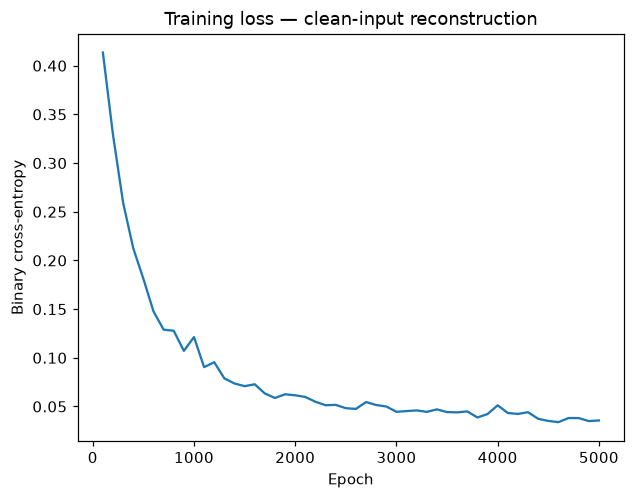

In [6]:
HIDDEN = (20, 10)
LATENT_DIM = 2
TRAIN_NOISE = 0.10
LEARNING_RATE = 0.01
EPOCHS = 5000
MODEL_SEED = 0

ae = Autoencoder(
    hidden=HIDDEN,
    latent_dim=LATENT_DIM,
    activation="tanh",
    seed=MODEL_SEED,
)

history = ae.fit(
    X_clean,
    epochs=EPOCHS,
    optimizer=Adam(lr=LEARNING_RATE),
    batch_size=32,
    noise_level=TRAIN_NOISE,
    seed=MODEL_SEED,
)
plt.plot(history["epoch"], history["loss"])
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy")
plt.title("Training loss — clean-input reconstruction")
plt.show()


## 5. Initial denoising performance
Evaluate new corruptions of the same 32 characters at 0%, 5%, 10%, 20% and 30% noise.

- **Pixel errors:** compare both input and reconstruction with the clean original; lower is better.
- **Exact reconstruction:** no wrong pixels; higher is better.
- **≤1-pixel rate:** fraction with at most one wrong pixel.

The first check uses one draw. The main evaluation uses 100 draws per level with validation noise seed 1000. Separate noise seed 2000 is reserved for the final evaluation.

### 5.1 One-draw check
Results above use one draw at 10% noise.

In [7]:
EVAL_NOISE_LEVELS = [0.0, 0.05, 0.10, 0.20, 0.30]
N_NOISE_DRAWS = 100
VALIDATION_NOISE_SEED = 1000
FINAL_NOISE_SEED = 2000


eval_rng = np.random.default_rng(1000)
X_noisy = add_noise(X_clean, 0.10, rng=eval_rng)
X_reconstructed = ae.reconstruct(X_noisy)

errors_before = pixel_errors(X_clean, X_noisy)
errors_after = pixel_errors(X_clean, X_reconstructed)

print(f"Mean errors before: {errors_before.mean():.2f}")
print(f"Mean errors after:  {errors_after.mean():.2f}")
print(f"Exact reconstructions: {(errors_after == 0).sum()} / {len(X_clean)}")


Mean errors before: 3.38
Mean errors after:  1.25
Exact reconstructions: 25 / 32


### 5.2 Repeated evaluation
Average over 100 noise draws per level.

In [9]:
noise_levels = [0.0, 0.05, 0.10, 0.20, 0.30]
n_draws = 100

# Validation noise: use separate seeds for the final evaluation later.
eval_rng = np.random.default_rng(1000)
noise_results = []

for p in noise_levels:
    input_errors = []
    output_errors = []

    for _ in range(n_draws):
        noisy = add_noise(X_clean, p, rng=eval_rng)
        reconstructed = ae.reconstruct(noisy)

        input_errors.append(pixel_errors(X_clean, noisy))
        output_errors.append(pixel_errors(X_clean, reconstructed))

    # Shape: (100 noise draws, 32 characters)
    input_errors = np.asarray(input_errors)
    output_errors = np.asarray(output_errors)

    noise_results.append({
        "noise": p,
        "input_errors": input_errors,
        "output_errors": output_errors,
        "mean_before": input_errors.mean(),
        "mean_after": output_errors.mean(),
        "exact_rate": (output_errors == 0).mean(),
        "within_one_rate": (output_errors <= 1).mean(),
    })

print(
    f"{'Noise':>7} | {'Errors before':>13} | {'Errors after':>12}"
    f" | {'Exact':>7} | {'≤1 pixel':>9}"
)
print("-" * 65)

for result in noise_results:
    print(
        f"{result['noise']:7.0%} | "
        f"{result['mean_before']:13.2f} | "
        f"{result['mean_after']:12.2f} | "
        f"{result['exact_rate']:7.1%} | "
        f"{result['within_one_rate']:9.1%}")

  Noise | Errors before | Errors after |   Exact |  ≤1 pixel
-----------------------------------------------------------------
     0% |          0.00 |         0.12 |   93.8% |     93.8%
     5% |          1.73 |         0.33 |   88.7% |     90.6%
    10% |          3.51 |         1.09 |   78.3% |     80.8%
    20% |          6.99 |         4.53 |   46.4% |     49.9%
    30% |         10.48 |         9.04 |   19.2% |     21.8%


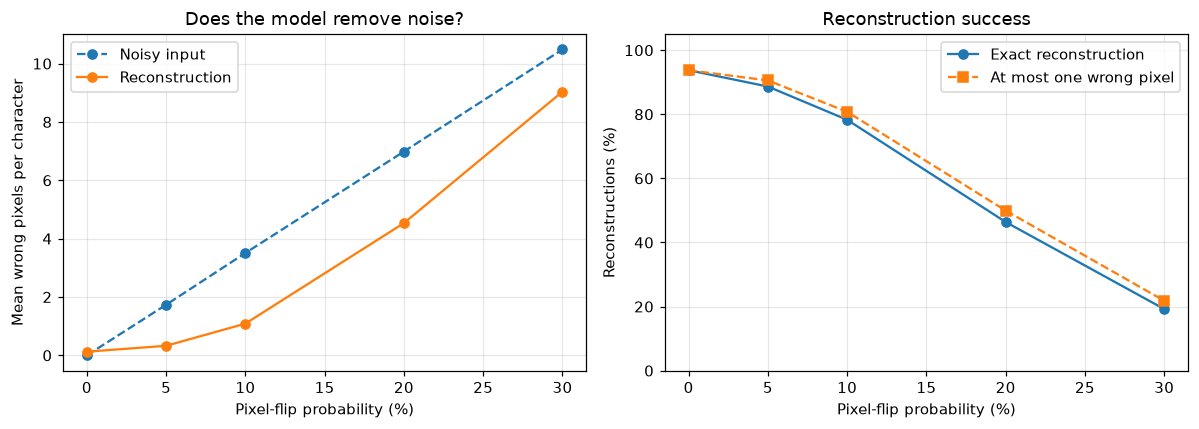

In [10]:
levels_pct = [100 * r["noise"] for r in noise_results]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    levels_pct,
    [r["mean_before"] for r in noise_results],
    "o--", label="Noisy input",
)
axes[0].plot(
    levels_pct,
    [r["mean_after"] for r in noise_results],
    "o-", label="Reconstruction",
)
axes[0].set(
    xlabel="Pixel-flip probability (%)",
    ylabel="Mean wrong pixels per character",
    title="Does the model remove noise?",
)
axes[0].legend()

axes[1].plot(
    levels_pct,
    [100 * r["exact_rate"] for r in noise_results],
    "o-", label="Exact reconstruction",
)
axes[1].plot(
    levels_pct,
    [100 * r["within_one_rate"] for r in noise_results],
    "s--", label="At most one wrong pixel",
)
axes[1].set(
    xlabel="Pixel-flip probability (%)",
    ylabel="Reconstructions (%)",
    ylim=(0, 105),
    title="Reconstruction success",
)
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 5.3 Initial failure examples
The following images show non-exact outputs from the one-draw check in 5.1.

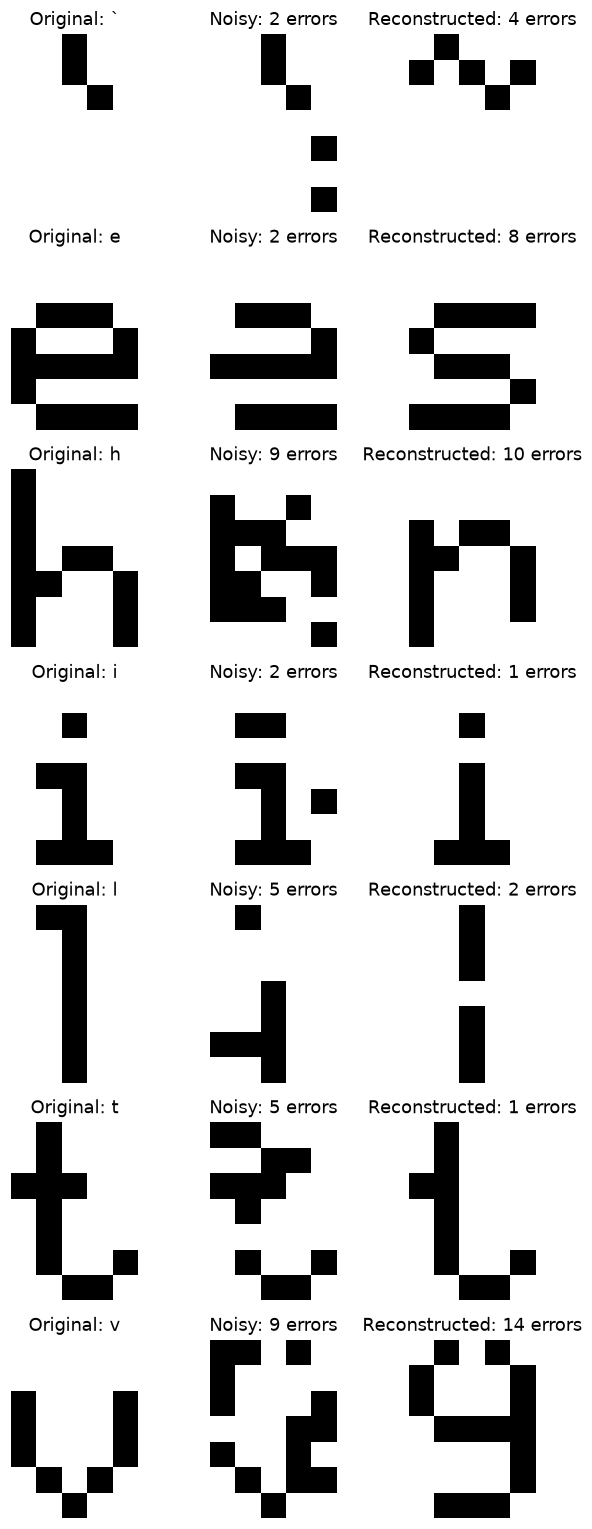

In [8]:
failed = np.flatnonzero(errors_after > 0)

if len(failed) == 0:
    print("All characters were reconstructed correctly.")
else:
    fig, axes = plt.subplots(
        len(failed), 3,
        figsize=(6, 2 * len(failed)),
        squeeze=False,
    )

    for row, i in enumerate(failed):
        images = [
            X_clean[i],
            X_noisy[i],
            np.round(X_reconstructed[i]),
        ]
        titles = [
            f"Original: {chars[i]}",
            f"Noisy: {errors_before[i]} errors",
            f"Reconstructed: {errors_after[i]} errors",
        ]

        for ax, image, title in zip(axes[row], images, titles):
            ax.imshow(image.reshape(7, 5), cmap="binary", vmin=0, vmax=1)
            ax.set_title(title)
            ax.axis("off")

    plt.tight_layout()
    plt.show()



**Result.** At 10% noise, mean errors fall from **3.51 to 1.09** (69% reduction), with **78.3%** exact reconstructions. Performance declines as noise increases; at 30%, only 19.2% are exact. On clean input, 30 of 32 characters are exact. Individual reconstructions can worsen despite the overall improvement.

## 6. Clean-trained reference
Train a fresh model with the same architecture, model seed and training settings, but **0% training noise**. Evaluate both models on identical noisy inputs to isolate the effect of denoising training.

In [11]:
ae_clean = Autoencoder(
    hidden=HIDDEN,
    latent_dim=LATENT_DIM,
    activation="tanh",
    seed=MODEL_SEED,
)

history_clean = ae_clean.fit(
    X_clean,
    epochs=EPOCHS,
    optimizer=Adam(lr=LEARNING_RATE),
    batch_size=32,
    noise_level=0.0,
    seed=MODEL_SEED,
)

### 6.1 Paired evaluation
Each model receives the same 100 noise draws per level. Report mean pixel errors and exact reconstruction rates.

In [12]:
comparison_rng = np.random.default_rng(1000)
comparison_results = []

for p in noise_levels:
    before = []
    clean_model_errors = []
    denoising_model_errors = []

    for _ in range(n_draws):
        noisy = add_noise(X_clean, p, rng=comparison_rng)

        before.append(pixel_errors(X_clean, noisy))
        clean_model_errors.append(
            pixel_errors(X_clean, ae_clean.reconstruct(noisy))
        )
        denoising_model_errors.append(
            pixel_errors(X_clean, ae.reconstruct(noisy))
        )

    before = np.asarray(before)
    clean_model_errors = np.asarray(clean_model_errors)
    denoising_model_errors = np.asarray(denoising_model_errors)

    comparison_results.append({
        "noise": p,
        "input_errors": before.mean(),
        "clean_errors": clean_model_errors.mean(),
        "denoising_errors": denoising_model_errors.mean(),
        "clean_exact": (clean_model_errors == 0).mean(),
        "denoising_exact": (denoising_model_errors == 0).mean(),
    })

print("Mean wrong pixels per character")
print(f"{'Noise':>7} | {'Input':>8} | {'Clean-trained':>14} | {'Denoising':>10}")
print("-" * 50)

for r in comparison_results:
    print(
        f"{r['noise']:7.0%} | "
        f"{r['input_errors']:8.2f} | "
        f"{r['clean_errors']:14.2f} | "
        f"{r['denoising_errors']:10.2f}"
    )

Mean wrong pixels per character
  Noise |    Input |  Clean-trained |  Denoising
--------------------------------------------------
     0% |     0.00 |           0.00 |       0.12
     5% |     1.73 |           4.48 |       0.33
    10% |     3.51 |           7.50 |       1.09
    20% |     6.99 |          10.85 |       4.53
    30% |    10.48 |          13.11 |       9.04


### 6.2 Comparison
Left: pixel errors (lower is better); dashed line: errors before reconstruction. Right: exact reconstruction rate (higher is better).

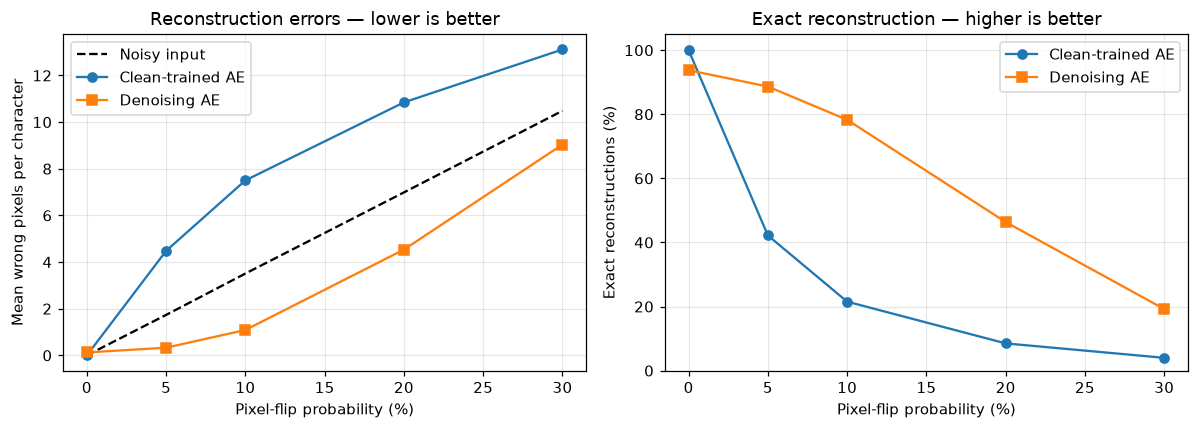

In [13]:
levels_pct = [100 * r["noise"] for r in comparison_results]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    levels_pct,
    [r["input_errors"] for r in comparison_results],
    "k--", label="Noisy input",
)
axes[0].plot(
    levels_pct,
    [r["clean_errors"] for r in comparison_results],
    "o-", label="Clean-trained AE",
)
axes[0].plot(
    levels_pct,
    [r["denoising_errors"] for r in comparison_results],
    "s-", label="Denoising AE",
)
axes[0].set(
    xlabel="Pixel-flip probability (%)",
    ylabel="Mean wrong pixels per character",
    title="Reconstruction errors — lower is better",
)

axes[1].plot(
    levels_pct,
    [100 * r["clean_exact"] for r in comparison_results],
    "o-", label="Clean-trained AE",
)
axes[1].plot(
    levels_pct,
    [100 * r["denoising_exact"] for r in comparison_results],
    "s-", label="Denoising AE",
)
axes[1].set(
    xlabel="Pixel-flip probability (%)",
    ylabel="Exact reconstructions (%)",
    ylim=(0, 105),
    title="Exact reconstruction — higher is better",
)

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Result.** The clean-trained model reconstructs all clean characters exactly, but increases mean errors at every nonzero noise level. At 10% noise, it gives **7.50 errors**, versus **1.09** for the denoising model and **3.51** in the input. Denoising training improves robustness at a small cost on clean inputs. This comparison uses model seed 0 and the initial 2D architecture.

## 7. Architecture comparison
First vary latent dimension, then hidden-layer width. Keep training noise at 10%, with Adam 0.01, batch size 32 and 5,000 epochs. Models share the same validation corruptions.

In [14]:
LATENT_CANDIDATES = [2, 4, 8]
HIDDEN_CANDIDATES = [(20, 10), (40, 20)]


### 7.1 Latent dimension — initial comparison
Compare latent dimensions 2, 4 and 8 with hidden layers `(20, 10)` and model seed 0.

In [15]:
latent_models = {}
latent_histories = {}

for latent_dim in [2, 4, 8]:
    print(f"Training latent dimension {latent_dim}...")

    model = Autoencoder(
        hidden=(20, 10),
        latent_dim=latent_dim,
        activation="tanh",
        seed=MODEL_SEED,
    )

    history = model.fit(
        X_clean,
        epochs=EPOCHS,
        optimizer=Adam(lr=LEARNING_RATE),
        batch_size=32,
        noise_level=TRAIN_NOISE,
        seed=MODEL_SEED,
    )

    latent_models[latent_dim] = model
    latent_histories[latent_dim] = history

print("Training complete.")

Training latent dimension 2...
Training latent dimension 4...
Training latent dimension 8...
Training complete.


In [16]:
architecture_rng = np.random.default_rng(1000)
latent_results = []

for p in noise_levels:
    errors_by_model = {dim: [] for dim in latent_models}

    for _ in range(n_draws):
        noisy = add_noise(X_clean, p, rng=architecture_rng)

        for dim, model in latent_models.items():
            errors = pixel_errors(X_clean, model.reconstruct(noisy))
            errors_by_model[dim].append(errors)

    for dim, errors in errors_by_model.items():
        errors = np.asarray(errors)

        latent_results.append({
            "latent_dim": dim,
            "noise": p,
            "mean_errors": errors.mean(),
            "exact_rate": (errors == 0).mean(),
        })

print(f"{'Noise':>7} | {'Latent 2':>10} | {'Latent 4':>10} | {'Latent 8':>10}")
print("-" * 46)

for p in noise_levels:
    values = {
        r["latent_dim"]: r["mean_errors"]
        for r in latent_results
        if r["noise"] == p
    }
    print(
        f"{p:7.0%} | {values[2]:10.2f} | "
        f"{values[4]:10.2f} | {values[8]:10.2f}"
    )

  Noise |   Latent 2 |   Latent 4 |   Latent 8
----------------------------------------------
     0% |       0.12 |       0.22 |       0.03
     5% |       0.33 |       0.33 |       0.18
    10% |       1.09 |       0.85 |       0.80
    20% |       4.53 |       3.89 |       4.23
    30% |       9.04 |       8.81 |       9.29


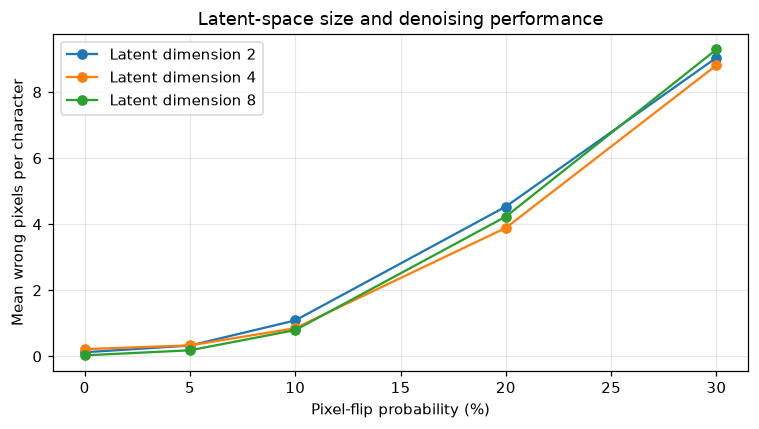

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))

for dim in latent_models:
    rows = [r for r in latent_results if r["latent_dim"] == dim]

    ax.plot(
        [100 * r["noise"] for r in rows],
        [r["mean_errors"] for r in rows],
        "o-",
        label=f"Latent dimension {dim}",
    )

ax.set(
    xlabel="Pixel-flip probability (%)",
    ylabel="Mean wrong pixels per character",
    title="Latent-space size and denoising performance",
)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Initial result.** Dimension 8 is best at 0–10% noise; dimension 4 is best at 20–30%. Repeat across model seeds before selecting a dimension.

### 7.2 Latent dimension — three model seeds
Reuse seed 0 and train seeds 1 and 2. Tables and error bars show **mean ± sample standard deviation across model seeds**, after averaging each model over 100 noise draws per level. Error bars are not confidence intervals.

In [18]:
models_by_seed = {
    (dim, MODEL_SEED): model
    for dim, model in latent_models.items()
}

for seed in [1, 2]:
    for dim in [2, 4, 8]:
        print(f"Training latent dimension {dim}, seed {seed}...")

        model = Autoencoder(
            hidden=(20, 10),
            latent_dim=dim,
            activation="tanh",
            seed=seed,
        )

        model.fit(
            X_clean,
            epochs=EPOCHS,
            optimizer=Adam(lr=LEARNING_RATE),
            batch_size=32,
            noise_level=TRAIN_NOISE,
            seed=seed,
        )

        models_by_seed[(dim, seed)] = model

print("Training complete.")

Training latent dimension 2, seed 1...
Training latent dimension 4, seed 1...
Training latent dimension 8, seed 1...
Training latent dimension 2, seed 2...
Training latent dimension 4, seed 2...
Training latent dimension 8, seed 2...
Training complete.


In [19]:
eval_rng = np.random.default_rng(1000)
seed_results = []

for p in noise_levels:
    # Generate once, then reuse for every model.
    noisy_inputs = [
        add_noise(X_clean, p, rng=eval_rng)
        for _ in range(n_draws)
    ]

    for (dim, seed), model in models_by_seed.items():
        errors = np.asarray([
            pixel_errors(X_clean, model.reconstruct(noisy))
            for noisy in noisy_inputs
        ])

        seed_results.append({
            "latent_dim": dim,
            "seed": seed,
            "noise": p,
            "mean_errors": errors.mean(),
            "exact_rate": (errors == 0).mean(),
        })

In [20]:
seed_summary = []

for p in noise_levels:
    for dim in [2, 4, 8]:
        values = np.array([
            r["mean_errors"]
            for r in seed_results
            if r["noise"] == p and r["latent_dim"] == dim
        ])

        seed_summary.append({
            "noise": p,
            "latent_dim": dim,
            "mean_errors": values.mean(),
            "std_errors": values.std(ddof=1),
        })

print("Mean pixel errors ± sample standard deviation across 3 model seeds")
print(f"{'Noise':>7} | {'Latent 2':>16} | {'Latent 4':>16} | {'Latent 8':>16}")
print("-" * 64)

for p in noise_levels:
    cells = []

    for dim in [2, 4, 8]:
        result = next(
            r for r in seed_summary
            if r["noise"] == p and r["latent_dim"] == dim
        )
        cells.append(
            f"{result['mean_errors']:.2f} ± {result['std_errors']:.2f}"
        )

    print(f"{p:7.0%} | {cells[0]:>16} | {cells[1]:>16} | {cells[2]:>16}")

Mean pixel errors ± sample standard deviation across 3 model seeds
  Noise |         Latent 2 |         Latent 4 |         Latent 8
----------------------------------------------------------------
     0% |      0.55 ± 0.46 |      0.20 ± 0.04 |      0.05 ± 0.07
     5% |      0.72 ± 0.39 |      0.32 ± 0.04 |      0.19 ± 0.07
    10% |      1.38 ± 0.27 |      0.84 ± 0.15 |      0.75 ± 0.08
    20% |      4.65 ± 0.10 |      3.92 ± 0.21 |      3.89 ± 0.30
    30% |      9.12 ± 0.10 |      8.67 ± 0.43 |      8.72 ± 0.51


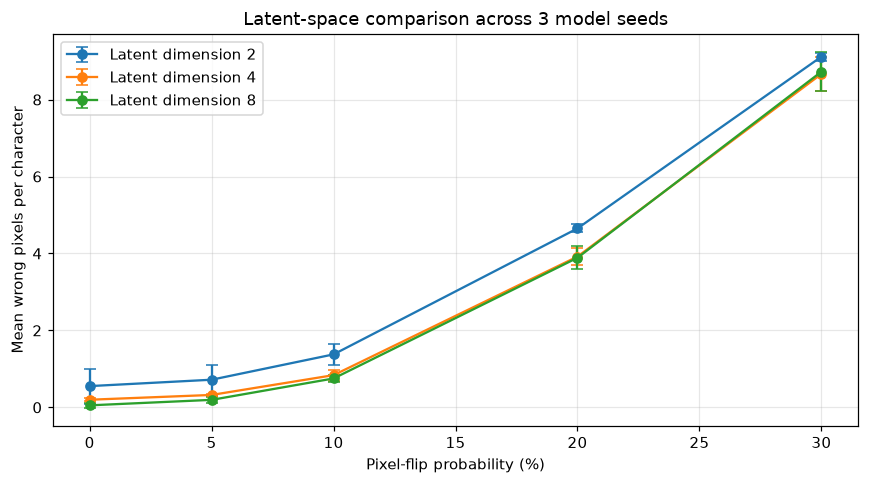

In [21]:
fig, ax = plt.subplots(figsize=(8, 4.5))

for dim in [2, 4, 8]:
    rows = [
        r for r in seed_summary
        if r["latent_dim"] == dim
    ]

    ax.errorbar(
        [100 * r["noise"] for r in rows],
        [r["mean_errors"] for r in rows],
        yerr=[r["std_errors"] for r in rows],
        marker="o",
        capsize=4,
        label=f"Latent dimension {dim}",
    )

ax.set(
    xlabel="Pixel-flip probability (%)",
    ylabel="Mean wrong pixels per character",
    title="Latent-space comparison across 3 model seeds",
)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Decision: latent dimension 8.** Dimensions 4 and 8 outperform dimension 2 in mean errors at every level. Dimension 8 is best at 0–10%; 4 and 8 are similar at 20–30% relative to seed variability. We carry 8 forward.

### 7.3 Hidden-layer width
With latent dimension 8, compare hidden layers `(20, 10)` and `(40, 20)` over three seeds. Reuse the smaller models and train only the wider models.

In [22]:
width_models = {
    ((20, 10), seed): models_by_seed[(8, seed)]
    for seed in [0, 1, 2]
}

for seed in [0, 1, 2]:
    print(f"Training hidden layers (40, 20), seed {seed}...")

    model = Autoencoder(
        hidden=(40, 20),
        latent_dim=8,
        activation="tanh",
        seed=seed,
    )

    model.fit(
        X_clean,
        epochs=EPOCHS,
        optimizer=Adam(lr=LEARNING_RATE),
        batch_size=32,
        noise_level=TRAIN_NOISE,
        seed=seed,
    )

    width_models[((40, 20), seed)] = model

print("Training complete.")

Training hidden layers (40, 20), seed 0...
Training hidden layers (40, 20), seed 1...
Training hidden layers (40, 20), seed 2...
Training complete.


In [23]:
width_rng = np.random.default_rng(1000)
width_results = []

for p in noise_levels:
    noisy_inputs = [
        add_noise(X_clean, p, rng=width_rng)
        for _ in range(n_draws)
    ]

    for (hidden, seed), model in width_models.items():
        errors = np.asarray([
            pixel_errors(X_clean, model.reconstruct(noisy))
            for noisy in noisy_inputs
        ])

        width_results.append({
            "hidden": hidden,
            "seed": seed,
            "noise": p,
            "mean_errors": errors.mean(),
            "exact_rate": (errors == 0).mean(),
        })

In [24]:
hidden_candidates = [(20, 10), (40, 20)]
width_summary = []

for p in noise_levels:
    for hidden in hidden_candidates:
        values = np.array([
            r["mean_errors"]
            for r in width_results
            if r["noise"] == p and r["hidden"] == hidden
        ])

        width_summary.append({
            "hidden": hidden,
            "noise": p,
            "mean_errors": values.mean(),
            "std_errors": values.std(ddof=1),
        })

print("Mean pixel errors ± sample standard deviation across 3 model seeds")
print(f"{'Noise':>7} | {'Hidden (20, 10)':>18} | {'Hidden (40, 20)':>18}")
print("-" * 51)

for p in noise_levels:
    cells = []

    for hidden in hidden_candidates:
        result = next(
            r for r in width_summary
            if r["noise"] == p and r["hidden"] == hidden
        )
        cells.append(
            f"{result['mean_errors']:.2f} ± {result['std_errors']:.2f}"
        )

    print(f"{p:7.0%} | {cells[0]:>18} | {cells[1]:>18}")

Mean pixel errors ± sample standard deviation across 3 model seeds
  Noise |    Hidden (20, 10) |    Hidden (40, 20)
---------------------------------------------------
     0% |        0.05 ± 0.07 |        0.00 ± 0.00
     5% |        0.19 ± 0.07 |        0.10 ± 0.04
    10% |        0.75 ± 0.08 |        0.48 ± 0.10
    20% |        3.89 ± 0.30 |        3.22 ± 0.21
    30% |        8.72 ± 0.51 |        7.90 ± 0.07


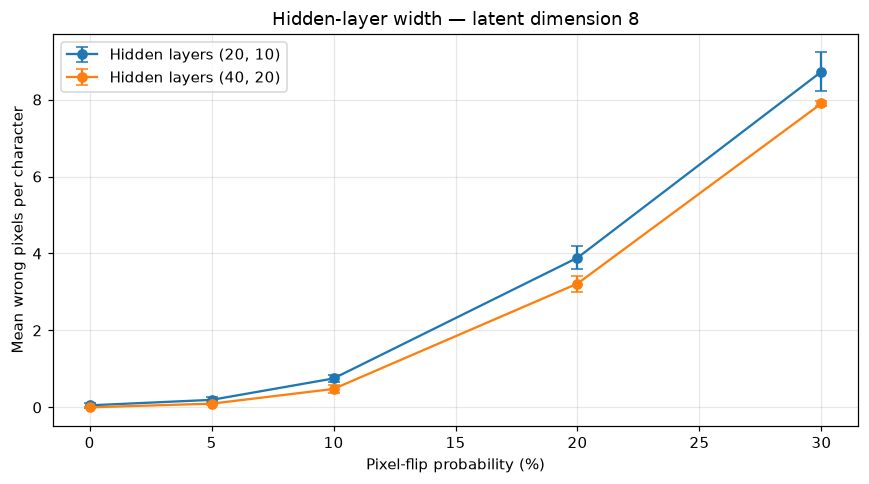

In [25]:
fig, ax = plt.subplots(figsize=(8, 4.5))

for hidden in hidden_candidates:
    rows = [
        r for r in width_summary
        if r["hidden"] == hidden
    ]

    ax.errorbar(
        [100 * r["noise"] for r in rows],
        [r["mean_errors"] for r in rows],
        yerr=[r["std_errors"] for r in rows],
        marker="o",
        capsize=4,
        label=f"Hidden layers {hidden}",
    )

ax.set(
    xlabel="Pixel-flip probability (%)",
    ylabel="Mean wrong pixels per character",
    title="Hidden-layer width — latent dimension 8",
)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Decision: hidden layers `(40, 20)`.** The wider network has lower mean errors at every level. At 10% noise, errors fall from **0.75 to 0.48** (36% reduction); all clean characters are exact for all three seeds. The selected architecture is **35–40–20–8–20–40–35**.

## 8. Training-noise comparison
Fix the selected architecture and compare 5%, 10% and 20% training noise over three model seeds. Reuse the 10% models. Evaluate all models on the same validation corruptions; heatmap rows are training noise and columns are evaluation noise.

In [26]:
TRAIN_NOISE_CANDIDATES = [0.05, 0.10, 0.20]


In [27]:
training_noise_levels = [0.05, 0.10, 0.20]
model_seeds = [0, 1, 2]

training_noise_models = {
    (0.10, seed): width_models[((40, 20), seed)]
    for seed in model_seeds
}

for train_noise in [0.05, 0.20]:
    for seed in model_seeds:
        print(f"Training noise {train_noise:.0%}, seed {seed}...")

        model = Autoencoder(
            hidden=(40, 20),
            latent_dim=8,
            activation="tanh",
            seed=seed,
        )

        model.fit(
            X_clean,
            epochs=EPOCHS,
            optimizer=Adam(lr=LEARNING_RATE),
            batch_size=32,
            noise_level=train_noise,
            seed=seed,
        )

        training_noise_models[(train_noise, seed)] = model

print("Training complete.")

Training noise 5%, seed 0...
Training noise 5%, seed 1...
Training noise 5%, seed 2...
Training noise 20%, seed 0...
Training noise 20%, seed 1...
Training noise 20%, seed 2...
Training complete.


In [28]:
noise_comparison_rng = np.random.default_rng(1000)
training_noise_results = []

for eval_noise in noise_levels:
    noisy_inputs = [
        add_noise(X_clean, eval_noise, rng=noise_comparison_rng)
        for _ in range(n_draws)
    ]

    for (train_noise, seed), model in training_noise_models.items():
        errors = np.asarray([
            pixel_errors(X_clean, model.reconstruct(noisy))
            for noisy in noisy_inputs
        ])

        training_noise_results.append({
            "train_noise": train_noise,
            "seed": seed,
            "eval_noise": eval_noise,
            "mean_errors": errors.mean(),
            "exact_rate": (errors == 0).mean(),
        })

In [30]:
training_noise_summary = []

for train_noise in training_noise_levels:
    for eval_noise in noise_levels:
        values = np.array([
            r["mean_errors"]
            for r in training_noise_results
            if r["train_noise"] == train_noise
            and r["eval_noise"] == eval_noise
        ])

        training_noise_summary.append({
            "train_noise": train_noise,
            "eval_noise": eval_noise,
            "mean_errors": values.mean(),
            "std_errors": values.std(ddof=1),
        })

print("Mean pixel errors ± sample standard deviation across 3 model seeds")
header = "Train noise | " + " | ".join(
    f"Eval {p:.0%}".center(13) for p in noise_levels
)
print(header)
print("-" * len(header))

for train_noise in training_noise_levels:
    cells = []

    for eval_noise in noise_levels:
        result = next(
            r for r in training_noise_summary
            if r["train_noise"] == train_noise
            and r["eval_noise"] == eval_noise
        )
        cells.append(
            f"{result['mean_errors']:.2f} ± {result['std_errors']:.2f}"
        )

    print(
        f"{train_noise:11.0%} | "
        + " | ".join(f"{cell:>13}" for cell in cells)
    )

Mean pixel errors ± sample standard deviation across 3 model seeds
Train noise |    Eval 0%    |    Eval 5%    |    Eval 10%   |    Eval 20%   |    Eval 30%  
-------------------------------------------------------------------------------------------
         5% |   0.01 ± 0.02 |   0.16 ± 0.06 |   0.79 ± 0.02 |   4.27 ± 0.11 |   8.89 ± 0.21
        10% |   0.00 ± 0.00 |   0.10 ± 0.04 |   0.48 ± 0.10 |   3.22 ± 0.21 |   7.90 ± 0.07
        20% |   0.11 ± 0.04 |   0.22 ± 0.04 |   0.47 ± 0.03 |   2.52 ± 0.06 |   6.75 ± 0.01


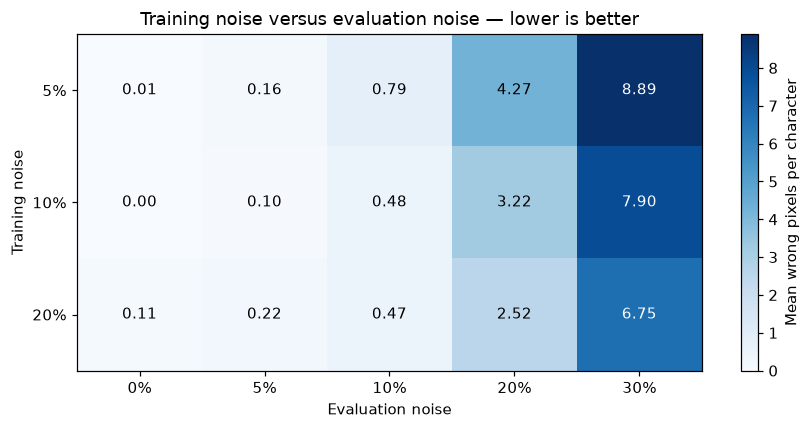

In [31]:
error_matrix = np.array([
    [
        next(
            r["mean_errors"]
            for r in training_noise_summary
            if r["train_noise"] == train_noise
            and r["eval_noise"] == eval_noise
        )
        for eval_noise in noise_levels
    ]
    for train_noise in training_noise_levels
])

fig, ax = plt.subplots(figsize=(8, 4))

image = ax.imshow(
    error_matrix,
    cmap="Blues",
    vmin=0,
    vmax=error_matrix.max(),
    aspect="auto",
)

ax.set_xticks(
    range(len(noise_levels)),
    [f"{p:.0%}" for p in noise_levels],
)
ax.set_yticks(
    range(len(training_noise_levels)),
    [f"{p:.0%}" for p in training_noise_levels],
)

for i in range(error_matrix.shape[0]):
    for j in range(error_matrix.shape[1]):
        value = error_matrix[i, j]
        ax.text(
            j, i, f"{value:.2f}",
            ha="center",
            va="center",
            color="white" if value > error_matrix.max() / 2 else "black",
        )

ax.set(
    xlabel="Evaluation noise",
    ylabel="Training noise",
    title="Training noise versus evaluation noise — lower is better",
)

fig.colorbar(image, ax=ax, label="Mean wrong pixels per character")
plt.tight_layout()
plt.show()

**Decision: 20% training noise.** Prioritising robustness across 5–30% corruption, we select 20%: it gives the lowest mean errors at 20–30% and is similar to 10% training noise at 10% evaluation noise. The trade-off is slightly worse clean and low-noise reconstruction; 10% training noise is best at 0–5%.

## 9. Final evaluation
Freeze the selected configuration and evaluate the three trained models on **100 new draws per noise level, seed 2000**. The configuration is not changed after this evaluation.

These are unseen corruptions of known training characters, not unseen characters. Standard deviations describe variation across the three model seeds.

In [32]:
SELECTED_TRAIN_NOISE = 0.20
FINAL_NOISE_SEED = 2000
FINAL_DRAWS = 100

final_models = {
    seed: training_noise_models[(SELECTED_TRAIN_NOISE, seed)]
    for seed in [0, 1, 2]
}

final_rng = np.random.default_rng(FINAL_NOISE_SEED)
final_results = []

for p in noise_levels:
    # The same final evaluation inputs are used for all three models.
    noisy_inputs = [
        add_noise(X_clean, p, rng=final_rng)
        for _ in range(FINAL_DRAWS)
    ]

    input_errors = np.asarray([
        pixel_errors(X_clean, noisy)
        for noisy in noisy_inputs
    ])

    for seed, model in final_models.items():
        output_errors = np.asarray([
            pixel_errors(X_clean, model.reconstruct(noisy))
            for noisy in noisy_inputs
        ])

        final_results.append({
            "noise": p,
            "seed": seed,
            "mean_input_errors": input_errors.mean(),
            "mean_output_errors": output_errors.mean(),
            "exact_rate": (output_errors == 0).mean(),
            "within_one_rate": (output_errors <= 1).mean(),
            "per_character_errors": output_errors.mean(axis=0),
        })

In [34]:
final_summary = []

for p in noise_levels:
    rows = [r for r in final_results if r["noise"] == p]

    output_means = np.array([r["mean_output_errors"] for r in rows])
    exact_rates = np.array([r["exact_rate"] for r in rows])

    final_summary.append({
        "noise": p,
        "mean_before": rows[0]["mean_input_errors"],
        "mean_after": output_means.mean(),
        "std_after": output_means.std(ddof=1),
        "exact_mean": exact_rates.mean(),
        "exact_std": exact_rates.std(ddof=1),
    })

print("Final evaluation — mean ± sample standard deviation across 3 model seeds")
print(
    f"{'Noise':>7} | {'Input errors':>12} | "
    f"{'Output errors':>17} | {'Exact reconstruction':>23}"
)
print("-" * 70)

for r in final_summary:
    output = f"{r['mean_after']:.2f} ± {r['std_after']:.2f}"
    exact = f"{100*r['exact_mean']:.1f}% ± {100*r['exact_std']:.1f} pp"

    print(
        f"{r['noise']:7.0%} | {r['mean_before']:12.2f} | "
        f"{output:>17} | {exact:>23}"
    )

Final evaluation — mean ± sample standard deviation across 3 model seeds
  Noise | Input errors |     Output errors |    Exact reconstruction
----------------------------------------------------------------------
     0% |         0.00 |       0.11 ± 0.04 |          93.8% ± 0.0 pp
     5% |         1.74 |       0.22 ± 0.03 |          90.5% ± 0.8 pp
    10% |         3.50 |       0.51 ± 0.05 |          84.5% ± 1.0 pp
    20% |         6.96 |       2.49 ± 0.03 |          58.8% ± 0.4 pp
    30% |        10.50 |       6.60 ± 0.06 |          25.9% ± 0.3 pp


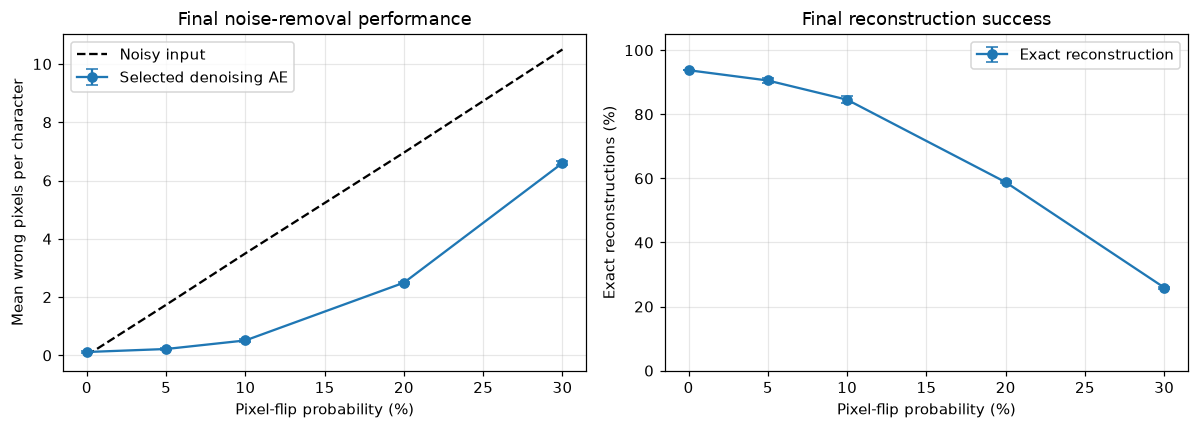

In [35]:
levels_pct = [100 * r["noise"] for r in final_summary]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    levels_pct,
    [r["mean_before"] for r in final_summary],
    "k--",
    label="Noisy input",
)
axes[0].errorbar(
    levels_pct,
    [r["mean_after"] for r in final_summary],
    yerr=[r["std_after"] for r in final_summary],
    marker="o",
    capsize=4,
    label="Selected denoising AE",
)
axes[0].set(
    xlabel="Pixel-flip probability (%)",
    ylabel="Mean wrong pixels per character",
    title="Final noise-removal performance",
)

axes[1].errorbar(
    levels_pct,
    [100 * r["exact_mean"] for r in final_summary],
    yerr=[100 * r["exact_std"] for r in final_summary],
    marker="o",
    capsize=4,
    label="Exact reconstruction",
)
axes[1].set(
    xlabel="Pixel-flip probability (%)",
    ylabel="Exact reconstructions (%)",
    ylim=(0, 105),
    title="Final reconstruction success",
)

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 9.1 Reconstruction examples
Selected successes and highest-error failures at 10% and 30% noise, using the final model with seed 0 and fresh noise seed 3000. These examples illustrate behaviour; they do not estimate average performance.

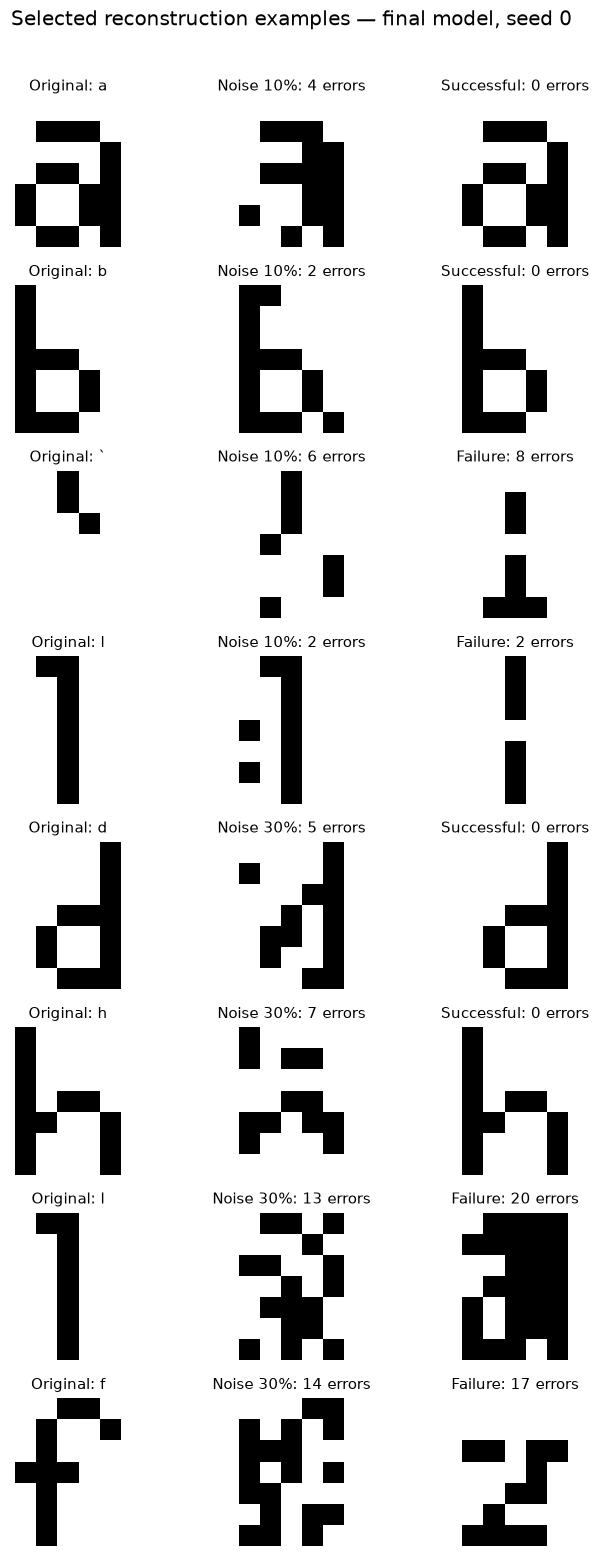

In [36]:
example_model = final_models[0]
example_rng = np.random.default_rng(3000)
examples = []

for p in [0.10, 0.30]:
    noisy = add_noise(X_clean, p, rng=example_rng)
    reconstructed = np.round(example_model.reconstruct(noisy))

    before = pixel_errors(X_clean, noisy)
    after = pixel_errors(X_clean, reconstructed)

    # Correct outputs where the input actually contained noise.
    successes = np.flatnonzero((after == 0) & (before > 0))[:2]

    # Show the two failures with the most remaining pixel errors.
    failures = np.flatnonzero(after > 0)
    failures = failures[np.argsort(after[failures])[::-1]][:2]

    for label, indices in [
        ("Successful", successes),
        ("Failure", failures),
    ]:
        for i in indices:
            examples.append({
                "noise": p,
                "label": label,
                "character": chars[i],
                "original": X_clean[i],
                "noisy": noisy[i],
                "reconstructed": reconstructed[i],
                "before": before[i],
                "after": after[i],
            })

if examples:
    fig, axes = plt.subplots(
        len(examples), 3,
        figsize=(7, 1.8 * len(examples)),
        squeeze=False,
    )

    for row, example in enumerate(examples):
        images = [
            example["original"],
            example["noisy"],
            example["reconstructed"],
        ]

        titles = [
            f"Original: {example['character']}",
            f"Noise {example['noise']:.0%}: {example['before']} errors",
            f"{example['label']}: {example['after']} errors",
        ]

        for ax, pixels, title in zip(axes[row], images, titles):
            ax.imshow(pixels.reshape(7, 5), cmap="binary", vmin=0, vmax=1)
            ax.set_title(title, fontsize=10)
            ax.axis("off")

    fig.suptitle(
        "Selected reconstruction examples — final model, seed 0",
        fontsize=13,
    )
    plt.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()
else:
    print("No examples selected.")

### 9.2 Errors by character
At 20% evaluation noise, rank characters by mean pixel errors across the final evaluation draws and three model seeds. Error bars show variation across model seeds.

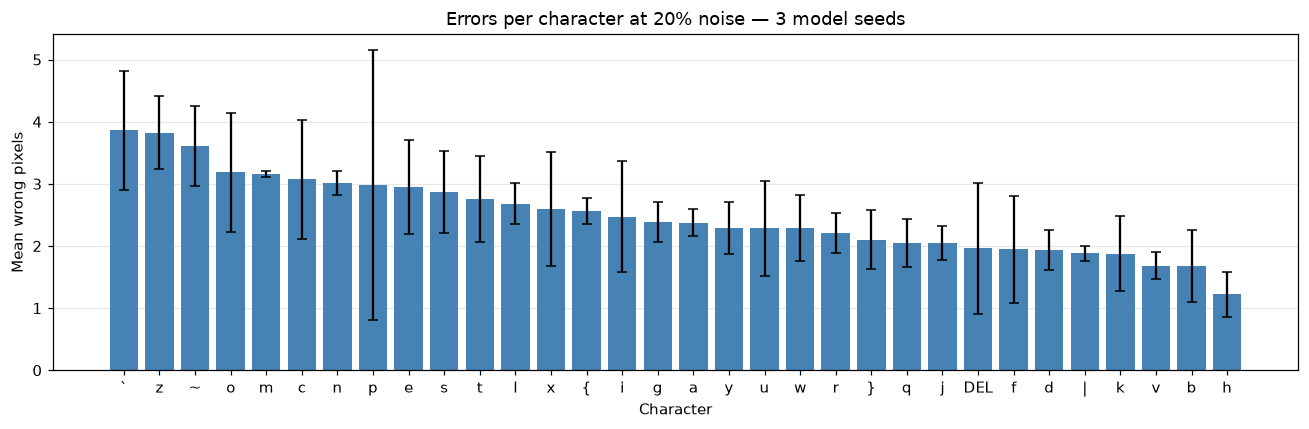

Five hardest characters:
  `: 3.86 ± 0.96
  z: 3.82 ± 0.59
  ~: 3.61 ± 0.64
  o: 3.18 ± 0.96
  m: 3.16 ± 0.05


In [37]:
CHARACTER_NOISE = 0.20

character_rows = [
    r for r in final_results
    if np.isclose(r["noise"], CHARACTER_NOISE)
]

# Shape: (3 model seeds, 32 characters).
character_errors = np.asarray([
    r["per_character_errors"] for r in character_rows
])

character_mean = character_errors.mean(axis=0)
character_std = character_errors.std(axis=0, ddof=1)
character_order = np.argsort(character_mean)[::-1]

fig, ax = plt.subplots(figsize=(12, 4))

ax.bar(
    range(len(chars)),
    character_mean[character_order],
    yerr=character_std[character_order],
    capsize=3,
    color="steelblue",
)

ax.set_xticks(range(len(chars)))
ax.set_xticklabels([chars[i] for i in character_order])
ax.set(
    xlabel="Character",
    ylabel="Mean wrong pixels",
    title=f"Errors per character at {CHARACTER_NOISE:.0%} noise — 3 model seeds",
)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

print("Five hardest characters:")
for i in character_order[:5]:
    print(f"{chars[i]:>3}: {character_mean[i]:.2f} ± {character_std[i]:.2f}")

### 9.3 Examples for the two hardest characters
For the final model with seed 0, generate 100 fresh corruptions per selected character (noise seed 3001). Show the example closest to that model's mean error, rather than its worst case.

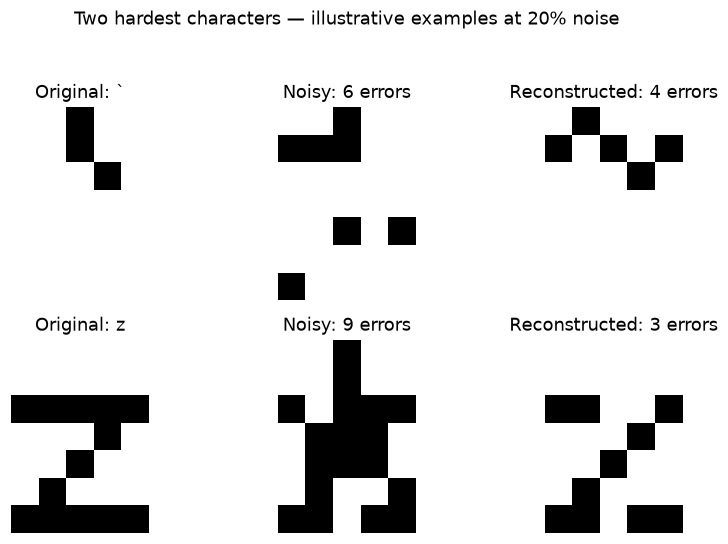

In [38]:
hardest_indices = character_order[:2]
example_model = final_models[0]
example_rng = np.random.default_rng(3001)

fig, axes = plt.subplots(2, 3, figsize=(8, 5))

for row, i in enumerate(hardest_indices):
    original = X_clean[i:i + 1]

    # Generate 100 noisy versions of this character.
    originals = np.repeat(original, 100, axis=0)
    noisy = add_noise(originals, CHARACTER_NOISE, rng=example_rng)
    reconstructed = example_model.reconstruct(noisy)

    before = pixel_errors(originals, noisy)
    after = pixel_errors(originals, reconstructed)

    # Choose the example closest to the mean output error.
    chosen = np.argmin(np.abs(after - after.mean()))

    images = [
        original[0],
        noisy[chosen],
        np.round(reconstructed[chosen]),
    ]
    titles = [
        f"Original: {chars[i]}",
        f"Noisy: {before[chosen]} errors",
        f"Reconstructed: {after[chosen]} errors",
    ]

    for ax, pixels, title in zip(axes[row], images, titles):
        ax.imshow(pixels.reshape(7, 5), cmap="binary", vmin=0, vmax=1)
        ax.set_title(title)
        ax.axis("off")

fig.suptitle(
    f"Two hardest characters — illustrative examples at {CHARACTER_NOISE:.0%} noise"
)
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

**Interpretation.** Backtick, z, tilde, o and m have the highest mean errors (**3.16–3.86**, versus **2.49** overall). Seed variability makes the exact ranking uncertain. The examples show partial recovery: backtick improves from 6 to 4 errors and z from 9 to 3. Reducing pixel errors does not guarantee an exact or recognisable character.

## 10. Conclusions

| Final setting | Value |
|---|---|
| Architecture | 35–40–20–8–20–40–35 |
| Hidden / latent / output activation | tanh / linear / sigmoid |
| Loss / optimizer | Binary cross-entropy / Adam, learning rate 0.01 |
| Training | 5,000 epochs, batch size 32, fresh 20% pixel-flip noise |

- **Architecture choice:** increasing latent dimension and hidden-layer width reduced validation errors. The selected model was evaluated with three seeds.
- **Benefit of denoising training:** the initial matched comparison showed much lower errors than clean-only training on noisy inputs.
- **Final performance:** at 10% noise, errors fall from **3.50 to 0.51** (85% reduction), with **84.5% exact reconstructions**. At 30%, errors fall from 10.50 to 6.60, but only 25.9% are exact.
- **Trade-off:** robustness to stronger noise comes with a small clean-input error (0.11 pixels; 93.8% exact).
- **Scope:** results cover new independent pixel-flip corruptions of the same 32 characters. Unseen characters, other noise types and reliability beyond three model seeds remain untested.